In [1]:
import sys
sys.path.insert(0, "../src")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from finnews_sentiment.features.preprocess import LABEL_NAMES

bundle = joblib.load("../models/best.joblib")
model = bundle["model"]
print(bundle["meta"])

{'model': 'tfidf 50000 1-2gram sublinear + linear svm C=0.3', 'test_accuracy': 0.9218, 'test_macro_f1': 0.9217}


In [2]:
test_clean = pd.read_csv("data/test_clean.csv").dropna(subset=["text_clean"]).reset_index(drop=True)

test_clean["pred"] = model.predict(test_clean["text_clean"])
test_clean["pred_name"] = test_clean["pred"].map(LABEL_NAMES)

# уверенность: насколько лучший класс оторвался от второго
scores = model.decision_function(test_clean["text_clean"])
top2 = np.sort(scores, axis=1)[:, -2:]
test_clean["margin"] = top2[:, 1] - top2[:, 0]

errors = test_clean[test_clean["pred"] != test_clean["label"]]
print("ошибок:", len(errors), "из", len(test_clean), f"({len(errors) / len(test_clean):.1%})")

ошибок: 594 из 7599 (7.8%)


In [3]:
print(classification_report(test_clean["label"], test_clean["pred"], target_names=list(LABEL_NAMES.values())))

              precision    recall  f1-score   support

       World       0.94      0.91      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.89      0.89      0.89      1899
    Sci/Tech       0.90      0.90      0.90      1900

    accuracy                           0.92      7599
   macro avg       0.92      0.92      0.92      7599
weighted avg       0.92      0.92      0.92      7599



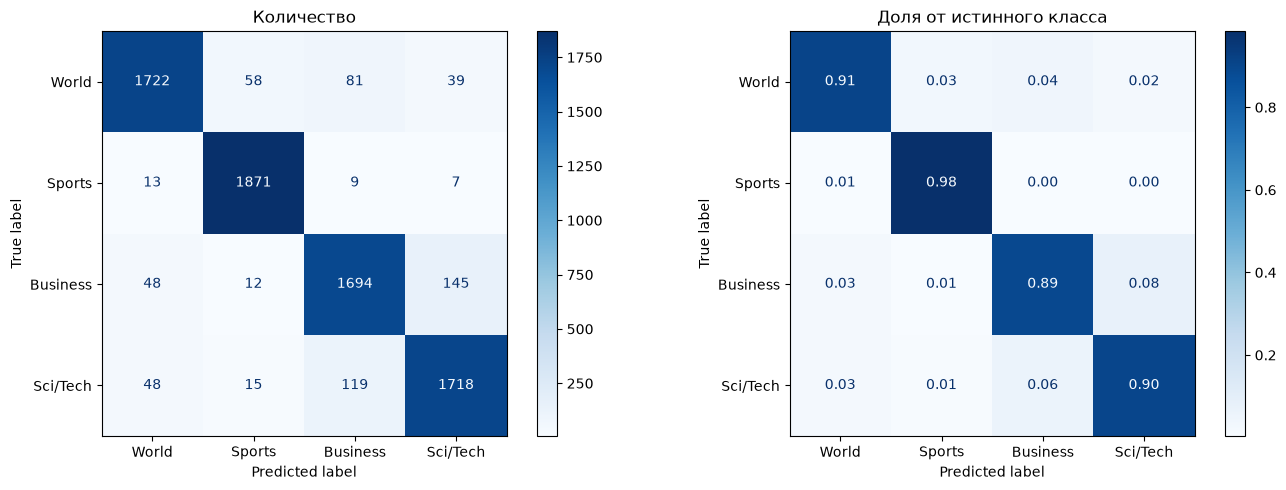

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = list(LABEL_NAMES.values())

ConfusionMatrixDisplay.from_predictions(test_clean["label"], test_clean["pred"],
                                        display_labels=names, cmap="Blues", ax=axes[0])
axes[0].set_title("Количество")

ConfusionMatrixDisplay.from_predictions(test_clean["label"], test_clean["pred"],
                                        display_labels=names, cmap="Blues", normalize="true",
                                        values_format=".2f", ax=axes[1])
axes[1].set_title("Доля от истинного класса")
plt.tight_layout()
plt.show()

In [5]:
pairs = errors.groupby(["label_name", "pred_name"]).size().sort_values(ascending=False)
pairs.head(8)

label_name  pred_name
Business    Sci/Tech     145
Sci/Tech    Business     119
World       Business      81
            Sports        58
Business    World         48
Sci/Tech    World         48
World       Sci/Tech      39
Sci/Tech    Sports        15
dtype: int64

In [6]:
for (true_name, pred_name) in pairs.head(4).index:
    print(f"===== правда: {true_name} -> модель: {pred_name} =====")
    sample = errors[(errors["label_name"] == true_name) & (errors["pred_name"] == pred_name)].head(4)
    for t in sample["text"]:
        print("-", t[:250])
    print()

===== правда: Business -> модель: Sci/Tech =====
- Intel to delay product aimed for high-definition TVs SAN FRANCISCO -- In the latest of a series of product delays, Intel Corp. has postponed the launch of a video display chip it had previously planned to introduce by year end, putting off a showdown
- Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive with discounters in the space -- which means that small businesses looking to mov
- Amazon Snaps Up China's Largest Web Retailer (NewsFactor) NewsFactor - Amazon.com (Nasdaq: AMZN) has said it will buy Joyo.com Limited -- a British Virgin Islands company that operates the largest Internet retail Web site in China -- for US #36;75 mi
- Deal has S2io champing at the gigabit OTTAWA -- A local firm that says it can help shrink backup times at large data centres is growing its business thanks to an alliance with Sun Microsyste

In [7]:
for _, row in errors.sort_values("margin", ascending=False).head(10).iterrows():
    print(f"[{row['label_name']} -> {row['pred_name']}, margin={row['margin']:.2f}]")
    print(row["text"][:250])
    print()

[Business -> Sci/Tech, margin=3.48]
Linux: Paris weighs a shift to open-source camp PARIS The open-source computer system known as Linux won a tough battle over Microsoft earlier this year when the city of Munich decided to change the operating software of 14,000 government computers, 

[Business -> Sci/Tech, margin=3.38]
Product Previews palmOneUpgrades Treo With Faster Chip, Better Display\With more than 600,000 units shipped, the Treo 600 is one of the big smartphone success stories. Last week, palmOne introduced the follow-on Treo 650 with a higher resolution 320-

[World -> Sports, margin=3.22]
Argentina Basketball Coach Magnano Quits Ruben Magnano, who coached Argentina to the Olympic basketball gold medal in Athens, resigned Thursday to accept a coaching job in Italy.

[Business -> Sci/Tech, margin=3.16]
34 tech firms sued for alleged LCD patent theft Honeywell has issued lawsuits against 34 companies, including Dell, Apple, Sony and Toshiba alleging LCD panels used in their pro

In [8]:
for _, row in errors.sort_values("margin").head(6).iterrows():
    print(f"[{row['label_name']} -> {row['pred_name']}, margin={row['margin']:.2f}]")
    print(row["text"][:250])
    print()

[Sports -> Sci/Tech, margin=0.00]
Supah Blitz captures Del Mar BC Handicap After spending the first 29 starts of his career mostly confined to the East Coast, Supah Blitz found out what everyone eventually does - it #39;s much better at Del Mar. In his 

[World -> Sci/Tech, margin=0.00]
Mich. Elephant Gets Therapy for Arthritis ROYAL OAK, Mich. - Like any patient, Wanda needs positive reinforcement to wrestle through her physical therapy...

[Sci/Tech -> Business, margin=0.00]
Thomson Joins Microsoft-Time Warner Deal (AP) AP - French technology company Thomson SA said Monday it was joining Microsoft Corp. and Time Warner Inc.'s proposed venture to make anti-piracy software, a move that could relieve European Union concerns

[Business -> World, margin=0.00]
Greenspan issues new warning over US current account deficit (AFP) AFP - US Federal Reserve chairman Alan Greenspan said the United States' huge current account deficit cannot be indefinitely financed by foreign countries and investo

In [9]:
test_clean["n_words"] = test_clean["text_clean"].str.split().str.len()
test_clean["length_group"] = pd.qcut(test_clean["n_words"], 4, labels=["короткие", "ниже среднего", "выше среднего", "длинные"])
test_clean["is_error"] = test_clean["pred"] != test_clean["label"]
test_clean.groupby("length_group", observed=True)["is_error"].mean().round(3)

length_group
короткие         0.109
ниже среднего    0.063
выше среднего    0.053
длинные          0.082
Name: is_error, dtype: float64

In [10]:
tfidf = model.named_steps["tfidf"]
clf = model.named_steps["clf"]
words = tfidf.get_feature_names_out()

for i, name in LABEL_NAMES.items():
    top = np.argsort(clf.coef_[i])[-15:][::-1]
    print(f"{name}: {', '.join(words[top])}")

World: canadian press, iraq, afp afp, iraqi, athens greece, york stock, palestinian, hostage, nuclear, arafat, afp, press canadian, troop, darfur, iran
Sports: coach, team, cup, sport, baseball, nba, player, quarterback, stadium, nascar, olympic, league, nhl, championship, season
Business: targetstocksquickinfofullquote, hellip, cbsmw, tax, economy, oil, bank, airline, halliburton, enron, investing, insurance, dow, economic, martha
Sci/Tech: nasa, space, internet, linux, scientist, software, reuters reuters, apple, washingtonpostcom, science, wifi, web, cybersecurity, online, arctic


In [11]:
errors[["text", "label_name", "pred_name", "margin"]].to_csv("../results/day05_errors.csv", index=False)

- длина текста: короткие тексты ошибаются в 2 раза чаще (10.9% против 5-6% у средних) - мало слов-подсказок;
  длинные тоже хуже (8.2%) - в них смешиваются слова разных тем
- интерпретация: топ-слова в основном осмысленные (iraq, nuclear / nba, coach / economy, oil, bank / nasa, linux, software)
- НО модель частично выучила источник новости: canadian press, afp (World), cbsmw - CBS MarketWatch (Business),
  reuters, washingtonpostcom (Sci/Tech). Это shortcut learning: на новостях из других источников качество может упасть
- нашёлся мусор, который пропустила очистка: hellip (html-сущность "многоточие")
  и targetstockquickinfofullquote (склеенный кусок ссылки на котировки)
- что улучшать дальше:
  - дочистить hellip и остатки ссылок в preprocess.py
  - проверить, как сильно модель зависит от источника: убрать названия агентств и сравнить качество
  - модели с контекстом (BERT), особенно для коротких текстов